![Logo SENATI](../00_Recursos/logo_senati.png)

**SENATI · Laboratorio práctico de IA y visión computacional**  
**Instructor:** Ing. Gunar Castro Iñigo  
**Tecnologías:** Python · OpenCV · NumPy · Matplotlib  
**Modalidad:** demostración → ejecución → interpretación → reto

# Aplicación resuelta 2 · Contador de piezas circulares

**Propósito:** Detectar y contar seis piezas circulares en una imagen de una mesa de trabajo.

**Actividad completada por:** COCA CCORPA LORENA ABIGAIL.  
**Fuente:** SEMANA 12 TALLER · SENATI.  
Se conservó el nombre original de este cuaderno. Las imágenes son las suministradas por el taller o transformaciones documentadas de ellas.

In [1]:
from pathlib import Path
import cv2
import numpy as np
import matplotlib.pyplot as plt

# Todos los cuadernos se ejecutan desde su propia carpeta.
RECURSOS = Path('..') / '00_Recursos'
SALIDAS = Path('resultados')
SALIDAS.mkdir(exist_ok=True)

def mostrar(imagen, titulo='Resultado', gris=False):
    """Muestra imágenes en Jupyter sin abrir ventanas externas."""
    plt.figure(figsize=(8, 4))
    if gris:
        plt.imshow(imagen, cmap='gray', vmin=0, vmax=255)
    else:
        plt.imshow(cv2.cvtColor(imagen, cv2.COLOR_BGR2RGB))
    plt.title(titulo)
    plt.axis('off')
    plt.show()

print('Entorno listo. OpenCV:', cv2.__version__)

Entorno listo. OpenCV: 4.13.0


## Situación práctica
En la línea de producción necesitamos **contar piezas circulares**. En la imagen también existe una pieza rectangular, que no debe contarse.

**Pasos:** escala de grises → umbral → contornos → circularidad → conteo → guardar.

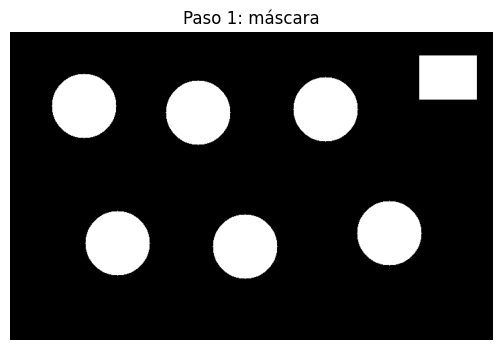

In [2]:
imagen = cv2.imread(str(RECURSOS / 'piezas.png'))
gris = cv2.cvtColor(imagen, cv2.COLOR_BGR2GRAY)
# Separación del fondo: las piezas coloreadas son oscuras.
_, mascara = cv2.threshold(gris, 225, 255, cv2.THRESH_BINARY_INV)
mostrar(mascara, 'Paso 1: máscara', gris=True)

Área=7078 | circularidad=0.89
Área=7078 | circularidad=0.89
Área=7078 | circularidad=0.89
Área=7078 | circularidad=0.89
Área=7078 | circularidad=0.89
Área=7078 | circularidad=0.89
Área=5525 | circularidad=0.77
Total de piezas circulares: 6


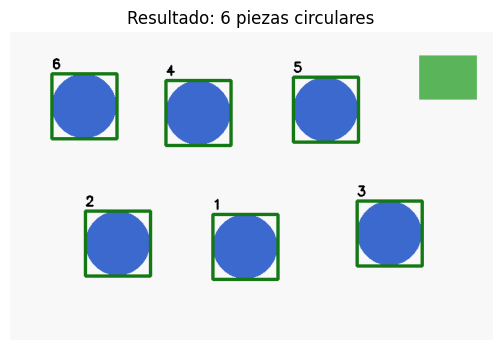

True

In [3]:
contornos, _ = cv2.findContours(mascara, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE)
resultado = imagen.copy()
conteo = 0
for c in contornos:
    area = cv2.contourArea(c)
    perimetro = cv2.arcLength(c, True)
    if area < 1000 or perimetro == 0:
        continue
    # Una circunferencia ideal tiene circularidad ~1.
    circularidad = 4 * np.pi * area / (perimetro ** 2)
    if circularidad > 0.78:
        conteo += 1
        x, y, w, h = cv2.boundingRect(c)
        cv2.rectangle(resultado, (x, y), (x+w, y+h), (20, 120, 20), 3)
        cv2.putText(resultado, str(conteo), (x, y-8), cv2.FONT_HERSHEY_SIMPLEX, .65,(0,0,0),2)
    print(f'Área={area:.0f} | circularidad={circularidad:.2f}')
print('Total de piezas circulares:', conteo)
assert conteo == 6, f'Se esperaban 6 piezas circulares y se detectaron {conteo}'
mostrar(resultado, f'Resultado: {conteo} piezas circulares')
cv2.imwrite(str(SALIDAS / 'piezas_contadas.png'), resultado)

**Explicación del instructor:** si hay dos piezas tocándose, el programa puede tratarlas como una sola región. La segmentación controlada es útil para aprender, pero un sistema industrial debe probar distintas posiciones, fondos y condiciones de luz.

**Reto:** modifica el límite de circularidad de `0.78` a `0.95`. ¿Se conserva el conteo? Justifica el resultado.

<div style="background-color:#FFF0A8;color:#463600;border-left:7px solid #D6A400;padding:14px 18px;border-radius:9px;margin:10px 0 16px"><strong>🟨 INICIO DEL DESARROLLO DE LA ACTIVIDAD</strong><br>Desde aquí se realiza el reto y sus comprobaciones. Se conserva el enunciado original y el código se ejecuta en orden.</div>

### Respuestas cortas

**¿Se conserva el conteo?** No: con circularidad **0.78** se cuentan **6**; con **0.95**, **0**. El umbral más estricto descarta contornos no perfectamente redondos.

## Ejecución del reto del estudiante (actividad resuelta)

In [4]:
# Actividad del estudiante: cambia la circularidad 0.78 por 0.95.
for umbral_circularidad in [0.78,0.95]:
    prueba_c=imagen.copy();cuantos=0
    for c in contornos:
        area=cv2.contourArea(c);peri=cv2.arcLength(c,True)
        if area<1000 or peri==0:continue
        circularidad=4*np.pi*area/(peri**2)
        if circularidad>=umbral_circularidad:
            cuantos+=1
            x,y,w,h=cv2.boundingRect(c)
            cv2.rectangle(prueba_c,(x,y),(x+w,y+h),(25,200,40),2)
    cv2.imwrite(str(SALIDAS/f'06_circularidad_{str(umbral_circularidad).replace(".","_")}.png'),prueba_c)
    print(f'Circularidad >= {umbral_circularidad}: {cuantos} piezas')
# Variante de foto: brillo ajustado de la imagen original (no inventa un nuevo conjunto de fotos).
variante=cv2.convertScaleAbs(imagen,alpha=0.85,beta=20)
cv2.imwrite(str(SALIDAS/'06_imagen_variante_brillo.png'),variante)

Circularidad >= 0.78: 6 piezas
Circularidad >= 0.95: 0 piezas


True

### Conclusión y evaluación

Al subir el umbral de circularidad a 0.95 se rechazan regiones menos perfectamente circulares. El conteo varía según la forma del contorno y el método de segmentación.

**Evidencia:** ejecutar todas las celdas; las imágenes guardadas en `resultados/` muestran el procesamiento. La captura del cuaderno abierto corresponde al estudiante una vez ejecutado en su máquina.